In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

%matplotlib inline

# ─── Load both datasets ───────────────────────────────────────────────────────
df_naive = pd.read_csv('output/binding/atp_interactions.csv')
df_fixed = pd.read_csv('output/binding_fixedresidue/atp_interactions.csv')

# Add a label column to each
df_naive['dataset'] = 'naive'
df_fixed['dataset'] = 'fixed_residue'

# Combined dataframe for joint analyses
df_combined = pd.concat([df_naive, df_fixed], ignore_index=True)

print(f'Naive structures:         {df_naive["pdb_id"].nunique()}')
print(f'Fixed residue structures: {df_fixed["pdb_id"].nunique()}')
print(f'Total interactions:       {len(df_combined)}')

Naive structures:         6
Fixed residue structures: 9
Total interactions:       167


# Residue Conservation 

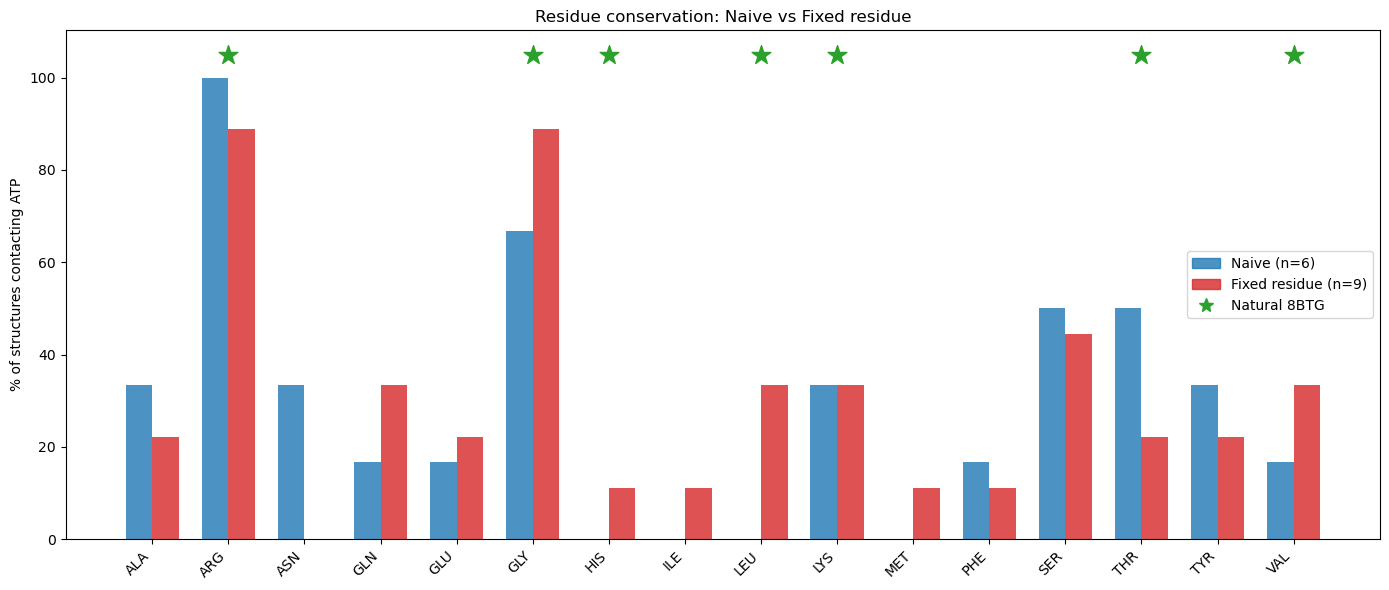

Saved comparison_residue_conservation.png


In [21]:
# ─── Step 2 — Side-by-side residue conservation ───────────────────────────────
n_naive = df_naive['pdb_id'].nunique()
n_fixed = df_fixed['pdb_id'].nunique()

res_naive = (
    df_naive.drop_duplicates(['pdb_id', 'res_type'])
            .groupby('res_type')['pdb_id']
            .count()
            .sort_values(ascending=False)
            / n_naive * 100
).head(15)

res_fixed = (
    df_fixed.drop_duplicates(['pdb_id', 'res_type'])
            .groupby('res_type')['pdb_id']
            .count()
            .sort_values(ascending=False)
            / n_fixed * 100
).head(15)

# Align on same residues
all_res = sorted(set(res_naive.index) | set(res_fixed.index))
res_naive = res_naive.reindex(all_res, fill_value=0)
res_fixed = res_fixed.reindex(all_res, fill_value=0)
natural_residues = ['VAL', 'GLY', 'LEU', 'LYS', 'THR', 'HIS', 'ARG']

x = np.arange(len(all_res))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - width/2, res_naive.values, width, label='Naive (n=6)', color='#1f77b4', alpha=0.8)
ax.bar(x + width/2, res_fixed.values, width, label='Fixed residue (n=9)', color='#d62728', alpha=0.8)

for i, res in enumerate(all_res):
    if res in natural_residues:
        ax.scatter(i, 105, marker='*', color='#2ca02c', s=200, zorder=5)

ax.set_xticks(x)
ax.set_xticklabels(all_res, rotation=45, ha='right')
ax.set_ylabel('% of structures contacting ATP')
ax.set_title('Residue conservation: Naive vs Fixed residue')

from matplotlib.lines import Line2D
ax.legend(handles=[
    plt.Rectangle((0,0),1,1, color='#1f77b4', alpha=0.8, label='Naive (n=6)'),
    plt.Rectangle((0,0),1,1, color='#d62728', alpha=0.8, label='Fixed residue (n=9)'),
    Line2D([0],[0], marker='*', color='#2ca02c', markersize=10, linestyle='None', label='Natural 8BTG')
])


plt.tight_layout()
plt.savefig('pictures/comparison_residue_conservation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved comparison_residue_conservation.png')

# Interaction Type Conservation

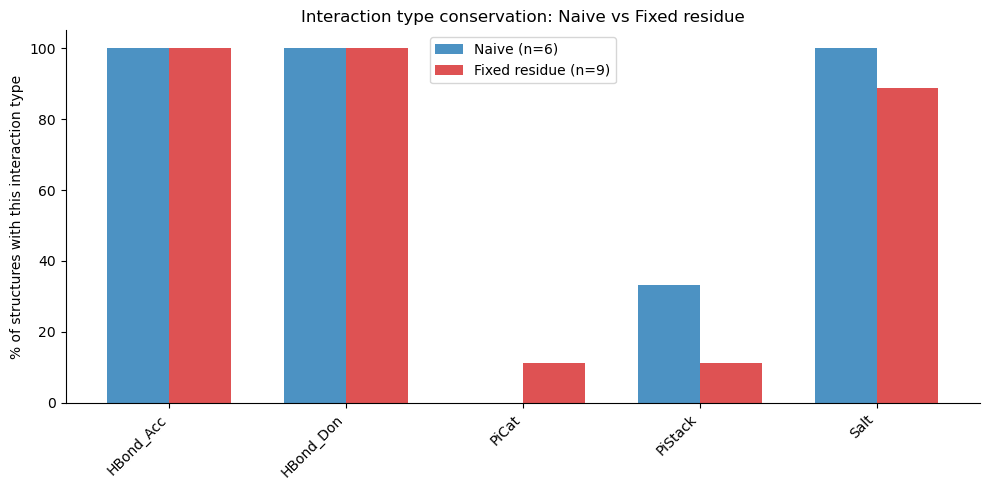

Saved comparison_itype_conservation.png


In [3]:
# ─── Step 3 — Side-by-side interaction type conservation ──────────────────────
itype_naive = (
    df_naive.drop_duplicates(['pdb_id', 'itype'])
            .groupby('itype')['pdb_id']
            .count()
            .sort_values(ascending=False)
            / n_naive * 100
)

itype_fixed = (
    df_fixed.drop_duplicates(['pdb_id', 'itype'])
            .groupby('itype')['pdb_id']
            .count()
            .sort_values(ascending=False)
            / n_fixed * 100
)

all_itypes = sorted(set(itype_naive.index) | set(itype_fixed.index))
itype_naive = itype_naive.reindex(all_itypes, fill_value=0)
itype_fixed = itype_fixed.reindex(all_itypes, fill_value=0)

x = np.arange(len(all_itypes))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, itype_naive.values, width, label='Naive (n=6)', color='#1f77b4', alpha=0.8)
ax.bar(x + width/2, itype_fixed.values, width, label='Fixed residue (n=9)', color='#d62728', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(all_itypes, rotation=45, ha='right')
ax.set_ylabel('% of structures with this interaction type')
ax.set_title('Interaction type conservation: Naive vs Fixed residue')
ax.legend()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('pictures/comparison_itype_conservation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved comparison_itype_conservation.png')

# Combined heatmap

In [ ]:


# ─── Step 4 — Combined heatmap ────────────────────────────────────────
fp_combined = (
    df_combined
    .groupby(['pdb_id', 'res_type', 'itype'])
    .size()
    .reset_index(name='count')
    .pivot_table(index='pdb_id', columns=['res_type', 'itype'],
                 values='count', aggfunc='sum')
    .fillna(0)
    .gt(0)
    .astype(int)
)

# Add natural 8BTG as a reference row
natural_interactions = {
    ('VAL', 'HBond_Don'): 1,
    ('GLY', 'HBond_Don'): 1,
    ('LEU', 'HBond_Don'): 1,
    ('LYS', 'HBond_Don'): 1,
    ('THR', 'HBond_Don'): 1,
    ('HIS', 'HBond_Don'): 1,
    ('ARG', 'HBond_Acc'): 1,
    ('HIS', 'PiStack'):   1,
    ('LYS', 'Salt'):      1,
    ('ARG', 'Salt'):      1,
}

# Build a row for 8BTG with same columns as fp_combined
natural_row = pd.Series(0, index=fp_combined.columns)
for (res, itype), val in natural_interactions.items():
    if (res, itype) in fp_combined.columns:
        natural_row[(res, itype)] = val
natural_row.name = '8BTG_natural'

fp_combined = pd.concat([fp_combined, natural_row.to_frame().T])
# Force HIS PiStack to appear even if no designed structure has it
if ('HIS', 'PiStack') not in fp_combined.columns:
    fp_combined[('HIS', 'PiStack')] = 0
fp_combined.loc['8BTG_natural', ('HIS', 'PiStack')] = 1


dataset_labels = df_combined.drop_duplicates('pdb_id').set_index('pdb_id')['dataset']
fp_combined['dataset'] = dataset_labels
fp_combined = fp_combined.sort_values('dataset')  # naive first, then fixed
dataset_col = fp_combined.pop('dataset')

plot_data = fp_combined.T
freq_mask = plot_data.sum(axis=1) / plot_data.shape[1] >= 0.03
plot_data = plot_data[freq_mask].sort_index(level='itype')

# Shorten x-axis labels
short_labels = [s.split('_model')[0][-15:] if 'model' in s else s[-15:] 
                for s in plot_data.columns]

fig_h = max(8, len(plot_data) * 0.4)
fig_w = max(10, fp_combined.shape[0] * 1.2)
fig, (ax_top, ax_main) = plt.subplots(
    2, 1, figsize=(fig_w, fig_h + 0.5),
    gridspec_kw={'height_ratios': [0.03, 1], 'hspace': 0.02}
)

dataset_array = np.array([
    0 if d == 'naive' else 1 if d == 'fixed_residue' else 2
    for d in dataset_col.values
]).reshape(1, -1)
ax_top.imshow(dataset_array, aspect='auto', cmap='brg', vmin=0, vmax=2)
ax_top.axis('off')

naive_patch   = mpatches.Patch(color='blue', label='Naive (n=6)')
fixed_patch   = mpatches.Patch(color='red',  label='Fixed residue (n=9)')
natural_patch = mpatches.Patch(color='green', label='Natural 8BTG')
ax_top.legend(handles=[naive_patch, fixed_patch, natural_patch], loc='upper right',
              fontsize=8, frameon=False, bbox_to_anchor=(1, 3))

sns.heatmap(
    plot_data,
    ax=ax_main,
    cmap='Blues',
    cbar=False,
    linewidths=0.5,
    xticklabels=short_labels,
    yticklabels=[f'{r}  {i}' for r, i in plot_data.index],
)
ax_main.set_ylabel('Feature  (residue · interaction type)', fontsize=9)
ax_main.set_xlabel('Structure', fontsize=9)
ax_main.tick_params(axis='x', labelsize=6, rotation=45)
ax_main.tick_params(axis='y', labelsize=7)

fig.suptitle('Combined ATP Binding Fingerprints — Naive vs Fixed residue', fontsize=12)
plt.tight_layout()
plt.savefig('pictures/comparison_combined_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved comparison_combined_heatmap.png')

/tmp/ipykernel_700892/114341304.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# Unique/Shared contacts between both sets

Shared contacts:              16
Only in naive:                3
Only in fixed residue:        10

Shared contacts:
  ALA  + HBond_Don
  ARG  + HBond_Acc
  ARG  + HBond_Don
  ARG  + Salt
  GLN  + HBond_Don
  GLU  + HBond_Acc
  GLY  + HBond_Acc
  GLY  + HBond_Don
  LYS  + Salt
  PHE  + PiStack
  SER  + HBond_Acc
  SER  + HBond_Don
  THR  + HBond_Acc
  THR  + HBond_Don
  TYR  + HBond_Acc
  VAL  + HBond_Don

Only in naive:
  ASN  + HBond_Acc
  ASN  + HBond_Don
  TYR  + PiStack

Only in fixed residue:
  ARG  + PiCat
  GLU  + HBond_Don
  HIS  + HBond_Acc
  ILE  + HBond_Don
  LEU  + HBond_Acc
  LEU  + HBond_Don
  LYS  + HBond_Don
  MET  + HBond_Acc
  PHE  + HBond_Don
  VAL  + HBond_Acc


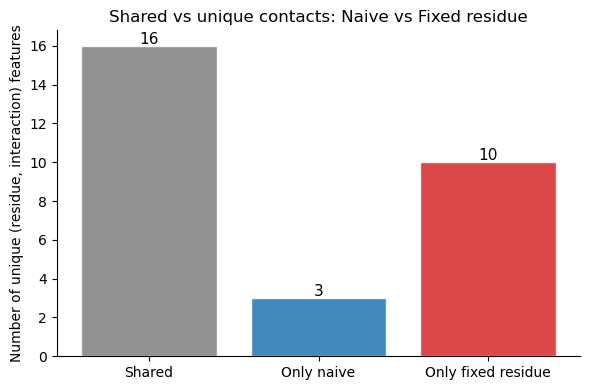

Saved comparison_unique_shared.png


In [ ]:
# ─── Step 5 — Unique and shared contacts ──────────────────────────────────────
# Get unique (res_type, itype) features for each dataset
features_naive = set(
    df_naive.groupby(['res_type', 'itype']).size().index.tolist()
)
features_fixed = set(
    df_fixed.groupby(['res_type', 'itype']).size().index.tolist()
)

shared = features_naive & features_fixed
only_naive = features_naive - features_fixed
only_fixed = features_fixed - features_naive

print(f'Shared contacts:              {len(shared)}')
print(f'Only in naive:                {len(only_naive)}')
print(f'Only in fixed residue:        {len(only_fixed)}')

print(f'\nShared contacts:')
for r, i in sorted(shared):
    print(f'  {r:4s} + {i}')

print(f'\nOnly in naive:')
for r, i in sorted(only_naive):
    print(f'  {r:4s} + {i}')

print(f'\nOnly in fixed residue:')
for r, i in sorted(only_fixed):
    print(f'  {r:4s} + {i}')

# Venn-style bar chart
fig, ax = plt.subplots(figsize=(6, 4))
categories = ['Shared', 'Only naive', 'Only fixed residue']
counts = [len(shared), len(only_naive), len(only_fixed)]
colors = ['#7f7f7f', '#1f77b4', '#d62728']

ax.bar(categories, counts, color=colors, edgecolor='white', alpha=0.85)
ax.set_ylabel('Number of unique (residue, interaction) features')
ax.set_title('Shared vs unique contacts: Naive vs Fixed residue')
for i, v in enumerate(counts):
    ax.text(i, v + 0.1, str(v), ha='center', fontsize=11)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('pictures/comparison_unique_shared.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved comparison_unique_shared.png')

## Interface SASA Comparison 

In [4]:
def calc_interface_sasa_pdb(pdb_path, atp_free_sasa):
    atp_full = get_atp_sasa_from_chains(pdb_path, ['A', 'B', 'Q'])
    atp_chainA = get_atp_sasa_from_chains(pdb_path, ['A', 'Q'])
    atp_chainB = get_atp_sasa_from_chains(pdb_path, ['B', 'Q'])

    buried_full = atp_free_sasa - atp_full
    buried_chainA = atp_free_sasa - atp_chainA
    buried_chainB = atp_free_sasa - atp_chainB

    return atp_full, buried_full, buried_chainA, buried_chainB

In [18]:
#Calculating atp_free_sasa
def calc_atp_free_sasa(pdb_path):
    atp_free = get_atp_sasa_from_chains(pdb_path, ['Q'])
    return atp_free

#Calculate once from first structure 
atp_free_sasa = calc_atp_free_sasa(
    '/work3/s253573/ATP-dependent-assembly/top9fixed_structures/rank1_ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1.pdb'
)
print(f'ATP free SASA: {atp_free_sasa:.1f} A^2')

ATP free SASA: 646.9 A^2


In [16]:
import freesasa
import logging
freesasa.setVerbosity(freesasa.silent)

st = freesasa.Structure('/work3/s253573/ATP-dependent-assembly/top6naive_for_download/design1_5_model_4_6.pdb', options={'hetatm': True})
res = freesasa.calc(st)
print([m for m in dir(res) if not m.startswith('_')])

['atomArea', 'nAtoms', 'residueAreas', 'totalArea', 'write_pdb']


In [19]:
import freesasa
import os
import pandas as pd

# Paths to your top structure folders
naive_dir = '/work3/s253573/ATP-dependent-assembly/top6naive_for_download'
fixed_dir = '/work3/s253573/ATP-dependent-assembly/top9fixed_structures'

import freesasa
import gemmi
import tempfile, os

freesasa.setVerbosity(freesasa.silent)

def get_atp_sasa_from_chains(pdb_path, chains_to_keep):
    st = gemmi.read_structure(pdb_path)
    # Remove unwanted chains
    for model in st:
        chains_to_remove = [c.name for c in model if c.name not in chains_to_keep]
        for cname in chains_to_remove:
            model.remove_chain(cname)
    with tempfile.NamedTemporaryFile(suffix='.pdb', mode='w', delete=False) as tmp:
        st.write_pdb(tmp.name)
        tmp_path = tmp.name
    structure = freesasa.Structure(tmp_path, options={'hetatm': True})
    res = freesasa.calc(structure)
    areas = res.residueAreas()
    atp_sasa = 0.0
    for chain in areas:
        for resnum, residue in areas[chain].items():
            if residue.residueType == 'ATP':
                atp_sasa += residue.total
    os.unlink(tmp_path)
    return atp_sasa

def calc_interface_sasa_pdb(pdb_path, atp_free_sasa):
    atp_full   = get_atp_sasa_from_chains(pdb_path, ['A', 'B', 'Q'])
    atp_chainA = get_atp_sasa_from_chains(pdb_path, ['A', 'Q'])
    atp_chainB = get_atp_sasa_from_chains(pdb_path, ['B', 'Q'])
    
    buried_full = atp_free_sasa - atp_full
    buried_chainA = atp_free_sasa - atp_chainA
    buried_chainB = atp_free_sasa - atp_chainB

    return atp_full, buried_full, buried_chainA, buried_chainB

results = []
for campaign, folder in [('naive', naive_dir), ('fixed_residue', fixed_dir)]:
    for fname in sorted(os.listdir(folder)):
        if not fname.endswith('.pdb'):
            continue
        pdb_path = os.path.join(folder, fname)
        try:
            atp_full, buried_full, buried_chainA, buried_chainB = calc_interface_sasa_pdb(pdb_path, atp_free_sasa)
            results.append({
                'structure': fname,
                'campaign': campaign,
                'atp_sasa_full': atp_full,
                'atp_buried_full': buried_full,
                'atp_buried_chainA': buried_chainA,
                'atp_buried_chainB': buried_chainB,
            })
        except Exception as e:
            print(f'WARNING: failed for {fname}: {e}')

df_sasa = pd.DataFrame(results)
print(df_sasa)

                                            structure       campaign  \
0                             design1_5_model_4_6.pdb          naive   
1                             design2_5_model_4_1.pdb          naive   
2                             design3_7_model_8_9.pdb          naive   
3                             design4_0_model_1_3.pdb          naive   
4                             design5_6_model_4_8.pdb          naive   
5                             design6_9_model_0_1.pdb          naive   
6   rank1_ATP_binding_8btg_ATP_binding_8btg_3_mode...  fixed_residue   
7   rank2_ATP_binding_8btg_ATP_binding_8btg_1_mode...  fixed_residue   
8   rank3_ATP_binding_8btg_ATP_binding_8btg_0_mode...  fixed_residue   
9   rank4_ATP_binding_8btg_ATP_binding_8btg_4_mode...  fixed_residue   
10  rank5_ATP_binding_8btg_ATP_binding_8btg_6_mode...  fixed_residue   
11  rank6_ATP_binding_8btg_ATP_binding_8btg_3_mode...  fixed_residue   
12  rank7_ATP_binding_8btg_ATP_binding_8btg_6_mode...  fixed_res

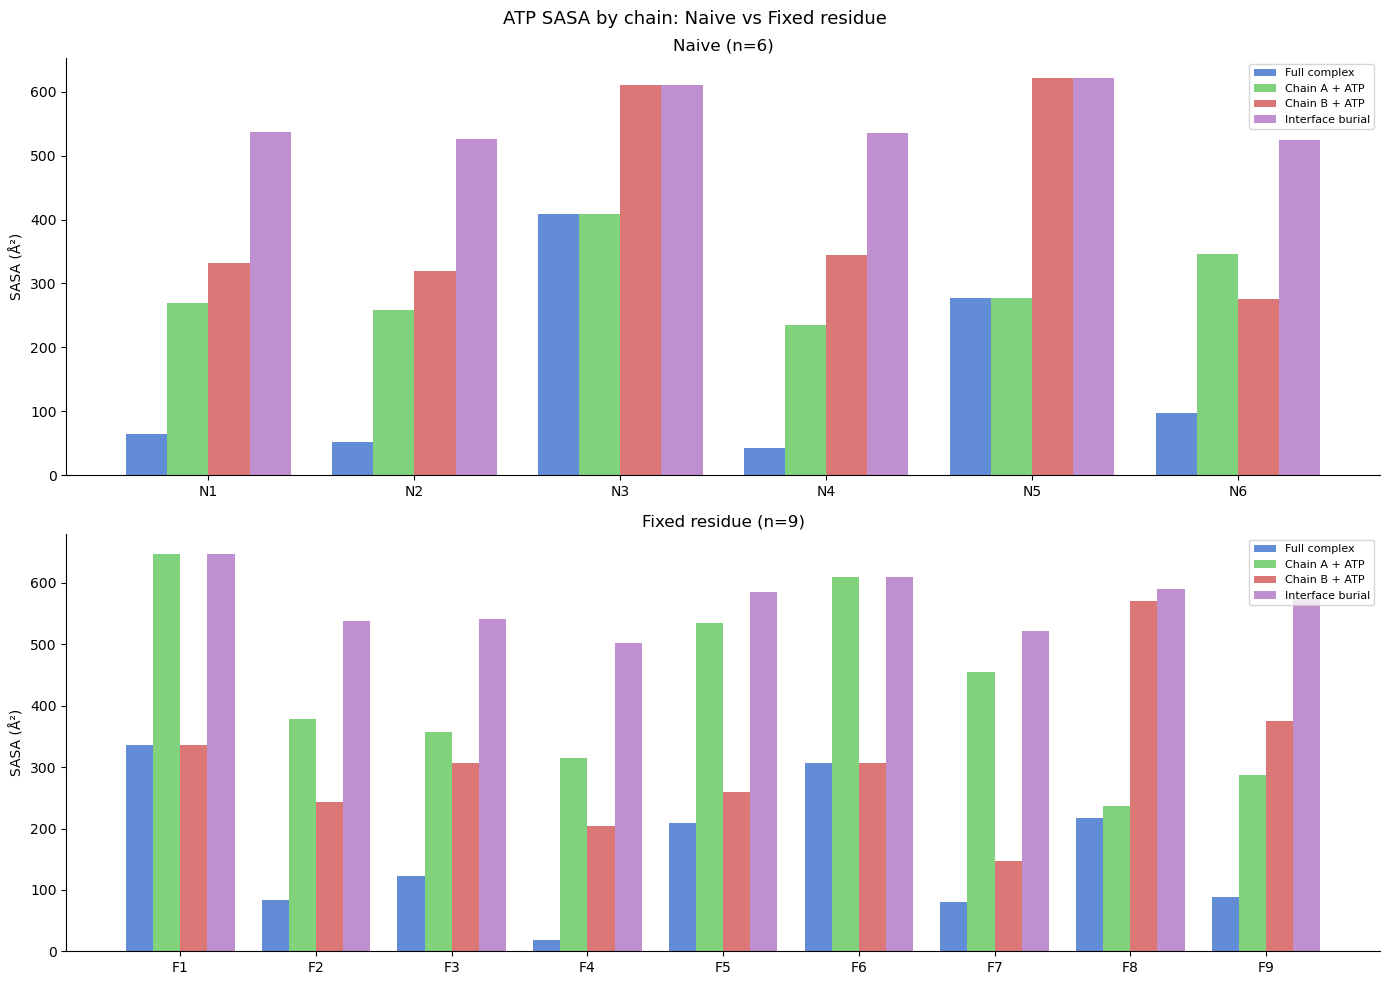

Saved comparison_interface_sasa.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Separate campaigns
df_naive = df_sasa[df_sasa['campaign'] == 'naive'].reset_index(drop=True)
df_fixed = df_sasa[df_sasa['campaign'] == 'fixed_residue'].reset_index(drop=True)

# Short labels
df_naive['label'] = [f'N{i+1}' for i in range(len(df_naive))]
df_fixed['label'] = [f'F{i+1}' for i in range(len(df_fixed))]

colors = ['#4878cf', '#6acc65', '#d65f5f', '#b47cc7']
metrics = ['atp_sasa_full', 'atp_sasa_chainA', 'atp_sasa_chainB', 'interface_burial']
metric_labels = ['Full complex', 'Chain A + ATP', 'Chain B + ATP', 'Interface burial']

for ax, df, title in [(axes[0], df_naive, 'Naive (n=6)'), (axes[1], df_fixed, 'Fixed residue (n=9)')]:
    x = np.arange(len(df))
    width = 0.2
    for i, (metric, label, color) in enumerate(zip(metrics, metric_labels, colors)):
        ax.bar(x + i * width, df[metric], width, label=label, color=color, alpha=0.85)
    ax.set_xticks(x + 1.5 * width)
    ax.set_xticklabels(df['label'])
    ax.set_ylabel('SASA (Å²)')
    ax.set_title(title)
    ax.legend(fontsize=8)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('ATP SASA by chain: Naive vs Fixed residue', fontsize=13)
plt.tight_layout()
plt.savefig('pictures/comparison_interface_sasa.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved comparison_interface_sasa.png')

## To see full structure names
### The ones with the lowest atp_sasa_full AND highest interface_burial are your best candidates — low full complex SASA means ATP is buried, and high interface burial means both chains are responsible.

In [ ]:
df_sasa_sorted = df_sasa.sort_values('interface_burial', ascending=False)
print(df_sasa_sorted[['structure', 'campaign', 'atp_sasa_full', 'interface_burial']].to_string())

for i, row in pd.concat([df_naive, df_fixed]).iterrows():
    print(row['label'], ':', row['structure'])

                                                           structure       campaign  atp_sasa_full  interface_burial
6    rank1_ATP_binding_8btg_ATP_binding_8btg_3_model_8_1_model_1.pdb  fixed_residue     336.036465        646.853109
4                                            design5_6_model_4_8.pdb          naive     277.939337        621.012542
2                                            design3_7_model_8_9.pdb          naive     409.376400        609.861924
11   rank6_ATP_binding_8btg_ATP_binding_8btg_3_model_0_1_model_0.pdb  fixed_residue     306.482394        608.953714
13   rank8_ATP_binding_8btg_ATP_binding_8btg_0_model_5_4_model_2.pdb  fixed_residue     217.239716        590.700818
10   rank5_ATP_binding_8btg_ATP_binding_8btg_6_model_0_2_model_3.pdb  fixed_residue     208.692072        585.562418
14  rank9_ATP_binding_8btg_ATP_binding_8btg_4_model_0_10_model_0.pdb  fixed_residue      88.248265        574.050754
8    rank3_ATP_binding_8btg_ATP_binding_8btg_0_model_9_3_model_0

## Final comparison with all the scores 

In [ ]:
# ─── Combined candidate ranking ───────────────────────────────────────────────

# Load scores for fixed residue campaign
df_fixed_scores = pd.read_csv('/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/8btg_D501_v3/shortlisted/final_monomer_filtered.csv')
df_naive_scores = pd.read_csv('/work3/s253573/projects/enzyme_design/atp_binding/conditioned_assembly/naive/shortlisted/final_monomer_filtered.csv')

df_fixed_scores['campaign'] = 'fixed_residue'
df_naive_scores['campaign'] = 'naive'
df_scores = pd.concat([df_fixed_scores, df_naive_scores], ignore_index=True)

# Merge with SASA results — match on structure name
# Strip path and extension from example_id to get bare name
df_scores['bare_id'] = df_scores['example_id'].apply(lambda x: x.split('/')[-1].replace('.cif.gz', ''))

# Match to SASA df
df_sasa['bare_id'] = df_sasa['structure'].str.replace('.pdb', '', regex=False)
# For fixed residue, filenames have rank prefix — extract the core name
df_sasa['bare_id'] = df_sasa['bare_id'].apply(lambda x: x.split('rank[0-9]+_')[-1] if 'rank' in x else x)

import re
df_sasa['bare_id'] = df_sasa['structure'].str.replace('.pdb', '', regex=False)
df_sasa['bare_id'] = df_sasa['bare_id'].apply(lambda x: re.sub(r'^rank\d+_', '', x))

df_merged = df_scores.merge(df_sasa[['bare_id', 'atp_sasa_full', 'atp_sasa_chainA', 'atp_sasa_chainB', 'interface_burial']], 
                             on='bare_id', how='left')

# ── Scoring ────────────────────────────────────────────────────────────────────
# Normalise each metric to 0-1 then combine
from sklearn.preprocessing import MinMaxScaler

df_merged['sasa_score']     = 1 - MinMaxScaler().fit_transform(df_merged[['atp_sasa_full']])
df_merged['ppdrop_score']   = MinMaxScaler().fit_transform(df_merged[['pp_drop']])
df_merged['mon_score']      = 1 - MinMaxScaler().fit_transform(df_merged[['avg_mon']])
df_merged['iptm_score']     = MinMaxScaler().fit_transform(df_merged[['best_iptm_pl']])

# Symmetry score — penalise asymmetric chain contributions
df_merged['chain_sym'] = 1 - (abs(df_merged['atp_sasa_chainA'] - df_merged['atp_sasa_chainB']) / 
                               (df_merged['atp_sasa_chainA'] + df_merged['atp_sasa_chainB']))

df_merged['combined_score'] = (
    0.35 * df_merged['ppdrop_score'] +
    0.25 * df_merged['sasa_score'] +
    0.20 * df_merged['mon_score'] +
    0.10 * df_merged['iptm_score'] +
    0.10 * df_merged['chain_sym']
)

df_ranked = df_merged.sort_values('combined_score', ascending=False).reset_index(drop=True)

print(df_ranked[['example_id', 'campaign', 'pp_drop', 'atp_sasa_full', 
                  'avg_mon', 'best_iptm_pl', 'chain_sym', 'combined_score']].to_string())